## 1. `date_score()` → date_score, remove ✅ 🧪 ❓ (VIII.2)

In [42]:
import math
import numpy as np
import pandas as pd

nulldurchgang=5
timeIntervall=30 #Days
def amplification(avg_dist):
    return np.maximum(1, 4 - np.asarray(avg_dist) / 14)

def date_score(amplification, repeat_score, dist_last):
    return 10  *  np.tanh(repeat_score*amplification / 30 * (np.asarray(dist_last) - nulldurchgang))

def averageDistances(dates):
    d = pd.to_datetime(pd.Series(dates)).sort_values()
    if len(d) < 2:
        return np.nan             # kein Abstand berechenbar
    return d.diff().dt.days.dropna().mean()

def maxDensity(dates, window=30):
    d = np.sort(pd.to_datetime(pd.Series(dates)).values.astype("datetime64[D]").astype(int))
    if len(d) == 0:
        return 0
    ends = np.searchsorted(d, d + window)          # erstes Datum außerhalb des Fensters
    return (ends - np.arange(len(d))).max()

2


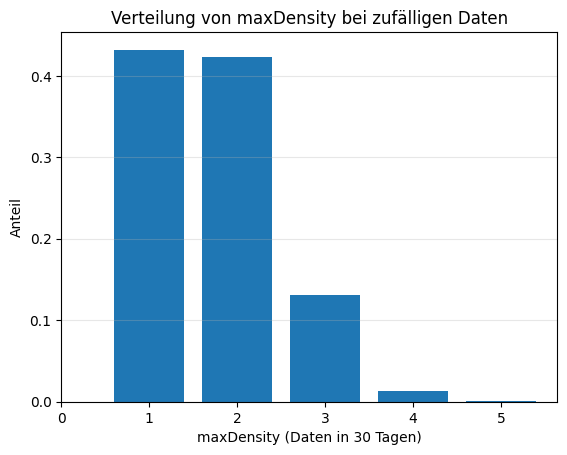

In [44]:
avg_dist=maxDensity(["2026-01-02", "2026-01-7", "2026-02-21"])
print(avg_dist)
rng = np.random.default_rng(0)
ergebnisse = []
for _ in range(5000):
    n = rng.integers(1, 6)                                  # 1 bis 5 Daten
    tage = rng.integers(0, 180, n)                          # zufällig in 6 Monaten
    dates = pd.Timestamp("2026-01-01") + pd.to_timedelta(tage, unit="D")
    ergebnisse.append(maxDensity(dates, window=30))         # Anzahl-Version

werte, anzahl = np.unique(ergebnisse, return_counts=True)
plt.bar(werte, anzahl / len(ergebnisse))
plt.xticks(range(6))
plt.xlabel("maxDensity (Daten in 30 Tagen)")
plt.ylabel("Anteil")
plt.title("Verteilung von maxDensity bei zufälligen Daten")
plt.grid(alpha=0.3, axis="y")
plt.show()

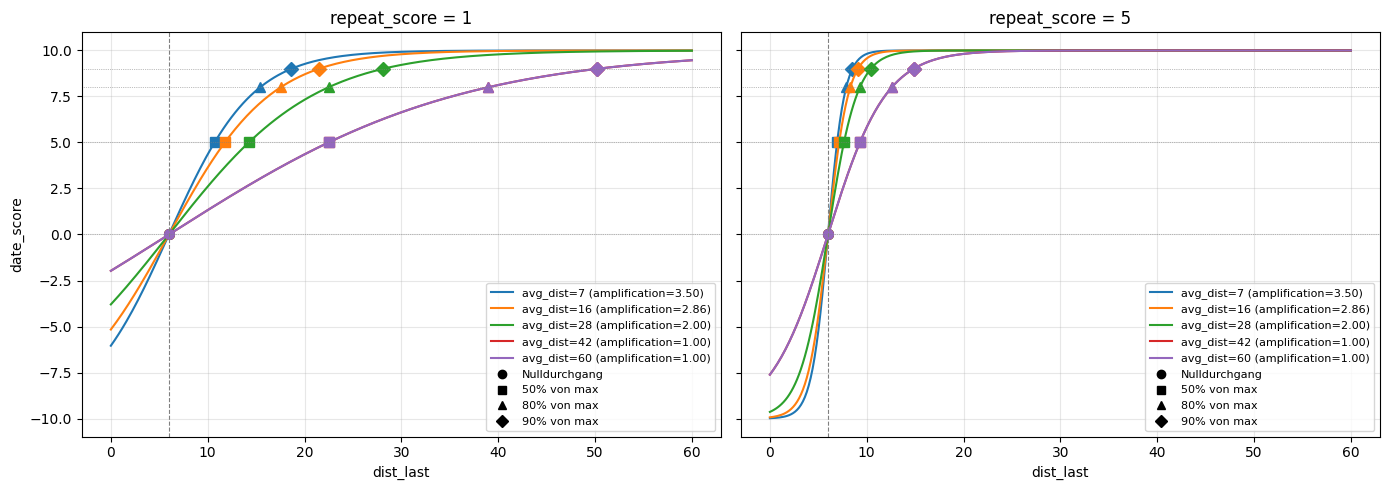

In [33]:
import numpy as np
import matplotlib.pyplot as plt

dist_last = np.linspace(0, 60, 300)
avg_dists = [7, 16, 28, 42, 60]
repeat_scores = [1, 5]
levels = {0: "o", 0.5: "s", 0.8: "^", 0.9: "D"}   # Anteil vom Maximum : Marker
max_score = 10

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, repeat_score in zip(axes, repeat_scores):
    for avg_dist in avg_dists:
        faktor = amplification(avg_dist)
        line, = ax.plot(dist_last, date_score(faktor, repeat_score, dist_last),
                        label=f"avg_dist={avg_dist} (amplification={faktor:.2f})")

        c = repeat_score * faktor / 30
        for p, m in levels.items():
            x = nulldurchgang + np.arctanh(p) / c
            if x <= dist_last.max():
                ax.plot(x, p * max_score, m, color=line.get_color(), ms=7)

    # Legende für die Markerformen und Hilfslinien für die Höhen
    for p, m in levels.items():
        ax.plot([], [], m, color="black", ls="",
                label="Nulldurchgang" if p == 0 else f"{p:.0%} von max")
        ax.axhline(p * max_score, color="gray", lw=0.5, ls=":")

    ax.axvline(nulldurchgang, color="gray", lw=0.8, ls="--")
    ax.set_xlabel("dist_last")
    ax.set_title(f"repeat_score = {repeat_score}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("date_score")
plt.tight_layout()
plt.show()

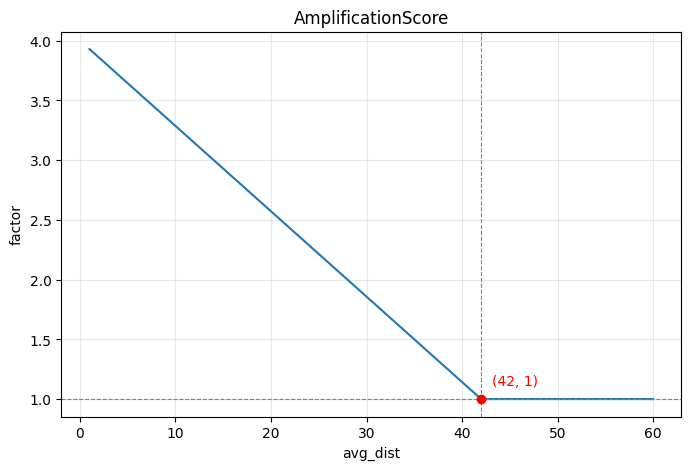

In [26]:
avg_dists = np.linspace(1, 60, 300)

x_cross = 14 * (4 - 1)        # = 42, where factor hits 1
y_cross = 1

plt.figure(figsize=(8, 5))
plt.plot(avg_dists, amplification(avg_dists))

plt.axhline(1, color="gray", lw=0.8, ls="--")
plt.axvline(x_cross, color="gray", lw=0.8, ls="--")
plt.scatter(x_cross, y_cross, color="red", zorder=5)
plt.annotate(f"({x_cross}, {y_cross})", (x_cross, y_cross),
             xytext=(8, 10), textcoords="offset points", color="red")

plt.xlabel("avg_dist")
plt.ylabel("factor")
plt.title("AmplificationScore")
plt.grid(alpha=0.3)
plt.show()

## Sanity Checks

Expected behavior. 🟠 = not tested yet; "old" = value from the old test script, re-check here.

| Situation | Expected | Status |
|---|---|---|
| just cooked | removed / 0 | 🟠 old: 0, removed |
| cooked within 4 days (incl. exactly 4) | removed | 🟠 old: removed |
| 5 days ago | not removed | 🟠 |
| cooked rarely, long ago | high (~2·repeat) | 🟠 old: 9.94 |
| normal rhythm, in between | medium | 🟠 old: 5.18 |
| never cooked | medium | 🟠 old: 5.00 |
| higher repeat ⇒ higher score | monotonically increasing | 🟠 |
| longer ago ⇒ higher score | monotonically increasing | 🟠 |
| always in [0, 10] | – | 🟠 |